In [1]:
# SUMMARY: Flower Image Classification Using a Neural Network
# The flower image dataset was downloaded and extracted, containing five categories:
# daisies, dandelions, roses, sunflowers, and tulips. The dataset folder was located,
# image filenames and labels were organized into CSV files, and the images were split
# into 80% training data and 20% evaluation data. Functions were created to read,
# resize, and normalize images to 224x224 pixels, and flower names were converted into
# numeric labels. The images were organized into batches of 16 for efficient processing.
# Sample images were displayed to verify that the images and labels were correct.
# A simple neural network was then built using a Flatten layer and a Dense output layer
# with Softmax activation. The model was compiled using the Adam optimizer, sparse
# categorical cross-entropy loss, and accuracy as the evaluation metric. The model was
# trained for 10 epochs, with validation performance monitored using the evaluation
# dataset. Training and validation loss and accuracy were plotted to observe learning
# progress. Finally, predictions were generated for evaluation images, and the predicted
# flower categories were displayed alongside the actual categories to assess performance.
#
# PURPOSE: To prepare the flower dataset, build and train a neural network, and evaluate
# its ability to classify images into five flower categories while understanding the main
# stages of an image classification workflow.

In [2]:
# CODE 1: Download and extract the flower dataset.
# Purpose: Downloads flower photos from the internet and extracts them
# into folders so Python can access the images.

import tensorflow as tf
import os

url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

path = tf.keras.utils.get_file(
    "flower_photos",
    origin=url,
    untar=True
)

print("Download and extraction completed.")
print("Returned path:", path)
print("Contents:", os.listdir(path))

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Download and extraction completed.
Returned path: /root/.keras/datasets/flower_photos
Contents: ['flower_photos']


In [3]:
# CODE 2: Find the correct dataset folder.
# Purpose: Searches for the folder containing all five flower categories:
# daisies, dandelions, roses, sunflowers, and tulips.

data_dir = None
search_root = "/root/.keras/datasets"

for root, dirs, files in os.walk(search_root):
    if all(name in dirs for name in [
        "daisy", "dandelion", "roses",
        "sunflowers", "tulips"
    ]):
        data_dir = root
        break

if data_dir is None:
    raise FileNotFoundError(
        "Flower folders were not found. Check the dataset download."
    )

print("Correct dataset directory:", data_dir)
print("Flower folders:", os.listdir(data_dir))

Correct dataset directory: /root/.keras/datasets/flower_photos/flower_photos
Flower folders: ['daisy', 'tulips', 'dandelion', 'roses', 'sunflowers', 'LICENSE.txt']


In [4]:
# CODE 3: Organize the images and create CSV files.
# Purpose: Records each image's filename and flower category, divides
# the images into 80% training data and 20% evaluation data, and saves
# the two lists as CSV files.

import pandas as pd
from sklearn.model_selection import train_test_split

CLASS_NAMES = [
    "daisy", "dandelion", "roses",
    "sunflowers", "tulips"
]

records = []

for label in CLASS_NAMES:
    folder = os.path.join(data_dir, label)

    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            records.append({
                "filename": os.path.join(label, filename),
                "label": label
            })

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("No flower images were found.")

train_df, eval_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

train_df.to_csv("/content/train_set.csv", index=False)
eval_df.to_csv("/content/eval_set.csv", index=False)

print("Total images:", len(df))
print("Training images:", len(train_df))
print("Evaluation images:", len(eval_df))

print("\nTraining CSV preview:")
print(train_df.head())

Total images: 3670
Training images: 2936
Evaluation images: 734

Training CSV preview:
                                    filename      label
1641       roses/8060338380_eb6c806624_n.jpg      roses
689   dandelion/16462263826_2555edeb74_n.jpg  dandelion
1664       roses/3171577977_8608282f04_m.jpg      roses
1555       roses/2713683760_d98cd2a05b_m.jpg      roses
2023       roses/4713531680_1110a2fa07_n.jpg      roses


In [5]:
# CODE 4: Define functions to prepare images and labels.
# Purpose: Opens each photo, resizes it to 224 × 224 pixels, scales
# pixel values to the range 0–1, and converts each flower name into
# a numeric label that the neural network can understand.

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_CHANNELS = 3

def read_and_decode(filename, resize_dims):
    # Read the image file.
    img_bytes = tf.io.read_file(filename)

    # Decode the file into a three-channel RGB image.
    img = tf.io.decode_image(
        img_bytes,
        channels=IMG_CHANNELS,
        expand_animations=False
    )

    # Scale pixel values to the range 0–1.
    img = tf.image.convert_image_dtype(img, tf.float32)

    # Resize the image to the required dimensions.
    img = tf.image.resize(img, resize_dims)

    # Return the prepared image.
    return img


def parse_csvline(csv_line):
    # Read the image filename and flower category from a CSV row.
    filename, label_string = tf.io.decode_csv(
        csv_line,
        record_defaults=["", ""]
    )

    # Build the complete path to the image file.
    image_path = tf.strings.join([
        data_dir, "/", filename
    ])

    # Load and resize the image.
    img = read_and_decode(
        image_path,
        [IMG_HEIGHT, IMG_WIDTH]
    )

    # Convert the flower category into its numeric label.
    # 0 = daisy, 1 = dandelion, 2 = roses,
    # 3 = sunflowers, 4 = tulips.
    label = tf.argmax(
        tf.cast(
            tf.equal(CLASS_NAMES, label_string),
            tf.int32
        ),
        output_type=tf.int32
    )

    # Return the image and its numeric label.
    return img, label

In [6]:
# CODE 5: Create the training and evaluation datasets.
# Purpose: Loads images and labels from the CSV files in batches of 16.
# The training dataset teaches the model, while the evaluation dataset
# checks how well the model performs on images set aside for evaluation.

train_dataset = (
    # Read the training CSV file.
    tf.data.TextLineDataset("/content/train_set.csv")

    # Skip the CSV column headings.
    .skip(1)

    # Load and prepare each image and its label.
    .map(parse_csvline, num_parallel_calls=tf.data.AUTOTUNE)

    # Group up to 16 images into each batch.
    .batch(16)

    # Prepare upcoming batches to improve loading efficiency.
    .prefetch(tf.data.AUTOTUNE)
)

eval_dataset = (
    # Read the evaluation CSV file.
    tf.data.TextLineDataset("/content/eval_set.csv")

    # Skip the CSV column headings.
    .skip(1)

    # Load and prepare each image and its label.
    .map(parse_csvline, num_parallel_calls=tf.data.AUTOTUNE)

    # Group up to 16 images into each batch.
    .batch(16)

    # Prepare upcoming batches to improve loading efficiency.
    .prefetch(tf.data.AUTOTUNE)
)

print("Training and evaluation datasets are ready.")

Training and evaluation datasets are ready.


In [7]:
# CODE 6: Check the image and label batches.
# Purpose: Checks whether the images and labels are loading correctly
# by displaying their dimensions and the numeric labels of the flowers.

# Take the first batch from the training dataset.
for image_batch, label_batch in train_dataset.take(1):

    # Display the dimensions of the image batch.
    # Expected for a full batch: (16, 224, 224, 3).
    print("Image batch shape:", image_batch.shape)

    # Display the dimensions of the labels.
    # Expected for a full batch: (16,).
    print("Label batch shape:", label_batch.shape)

    # Display the numeric label assigned to each image.
    print("Numeric labels:", label_batch.numpy())

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Numeric labels: [2 1 2 2 2 0 3 2 3 4 4 4 1 2 2 4]


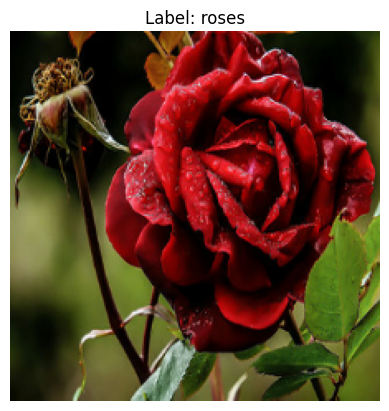

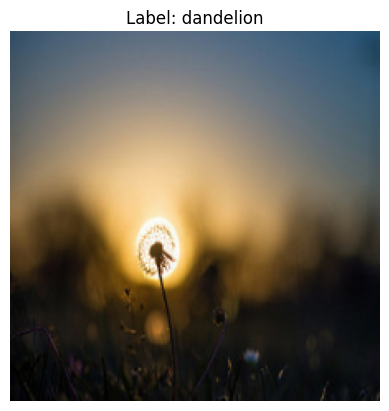

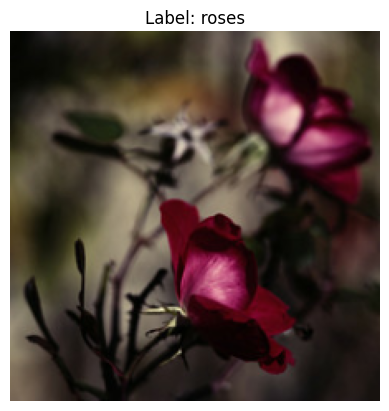

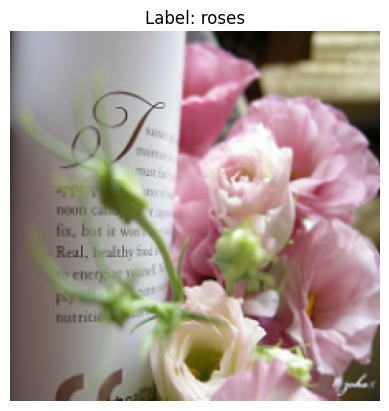

In [8]:
# CODE 7: Display four sample flower images.
# Purpose: Shows four photos with their flower category names to check
# that the images load correctly and their labels match before training.

import matplotlib.pyplot as plt

# Take the first batch from the training dataset.
for image_batch, label_batch in train_dataset.take(1):

    # Select up to four images from the batch.
    for i in range(min(4, len(image_batch))):

        # Select one image.
        image = image_batch[i]

        # Convert its numeric label into a Python integer.
        label = int(label_batch[i].numpy())

        # Display the flower image.
        plt.imshow(image.numpy())

        # Show the flower category above the image.
        plt.title(f"Label: {CLASS_NAMES[label]}")

        # Hide the axes for a cleaner display.
        plt.axis("off")

        # Display the image and its category.
        plt.show()

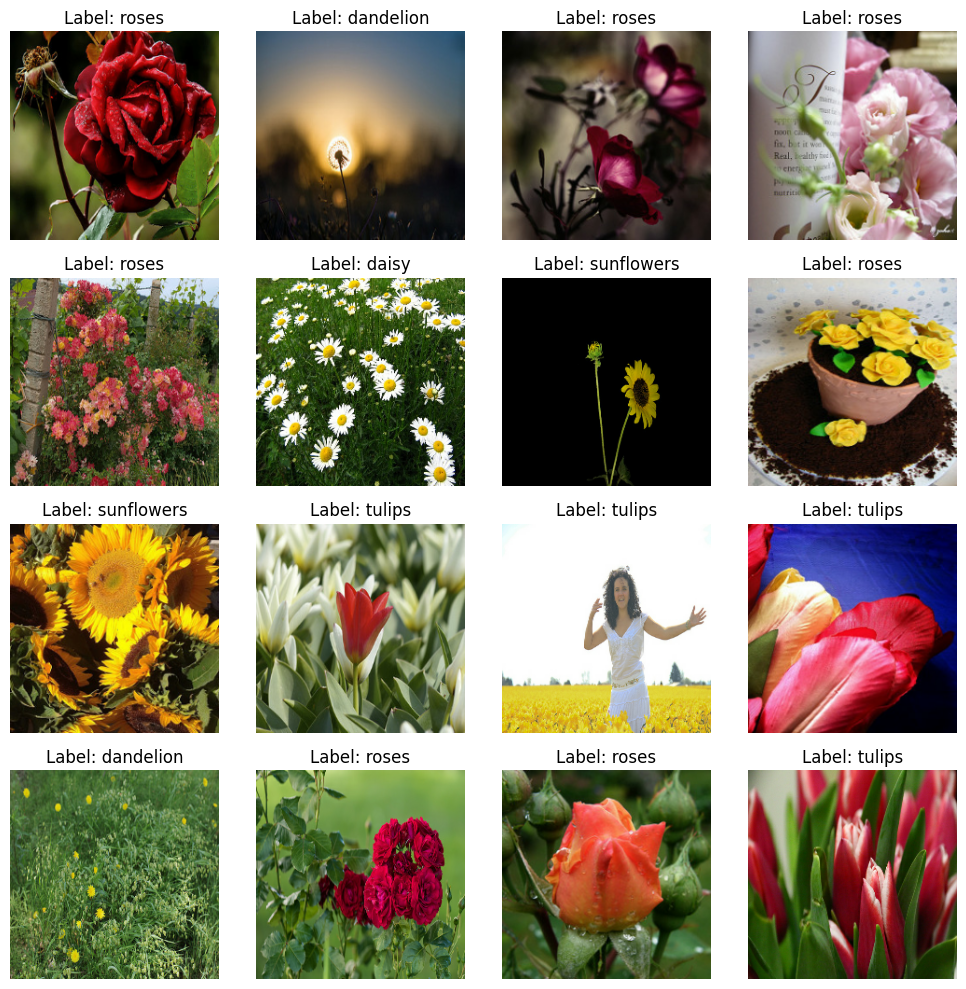

In [9]:
# Purpose: Displays 16 training flower images in a 4×4 grid with their category labels to verify that the images are loaded and labelled correctly.
# this is a proof that our image reading pipeline is working . we are able to fetch the images,and also able to fetch the correponding labels and teh labels have been converted to numbers from 0-4
# so the indivisual image and batch visualisation, our tensorflow pipeline for reading and convecting images to teh specific format is working
import matplotlib.pyplot as plt

# Take one batch from the training dataset. You can take 2, take 3 to see multiple batches
for image_batch, label_batch in train_dataset.take(1):
    fig, axes = plt.subplots(4, 4, figsize=(10, 10))

    for i in range(min(16, len(image_batch))):
        ax = axes[i // 4, i % 4]
        label = int(label_batch[i].numpy())

        ax.imshow(image_batch[i].numpy())
        ax.set_title(f"Label: {CLASS_NAMES[label]}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [10]:
# Purpose: Builds and compiles a simple neural network that learns to classify flower images into five categories, using Softmax to predict class probabilities, Adam to optimize learning, and accuracy to measure correct predictions.

from tensorflow import keras

model = keras.Sequential([
    keras.layers.Flatten(input_shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)),
    keras.layers.Dense(len(CLASS_NAMES), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=["accuracy"]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [11]:
# Purpose: Trains the neural network on the flower training dataset for 10 epochs, checks its performance on the evaluation dataset after each epoch, and stores the training history so we can review accuracy and loss over time.

EPOCHS = 10

history = model.fit(
    train_dataset,
    validation_data=eval_dataset,
    epochs=EPOCHS
)

Epoch 1/10
    183/Unknown 9s 44ms/step - accuracy: 0.3037 - loss: 23.1233

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


184/184 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.3389 - loss: 14.2888 - val_accuracy: 0.4441 - val_loss: 6.0198
Epoch 2/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - accuracy: 0.3944 - loss: 10.4523 - val_accuracy: 0.3856 - val_loss: 12.3276
Epoch 3/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step - accuracy: 0.4639 - loss: 8.3038 - val_accuracy: 0.3719 - val_loss: 21.8309
Epoch 4/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 20s 57ms/step - accuracy: 0.4550 - loss: 10.7594 - val_accuracy: 0.3924 - val_loss: 23.5132
Epoch 5/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 19s 51ms/step - accuracy: 0.4932 - loss: 9.9999 - val_accuracy: 0.2861 - val_loss: 29.4521
Epoch 6/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 20s 111ms/step - accuracy: 0.5456 - loss: 7.7455 - val_accuracy: 0.3706 - val_loss: 24.4168
Epoch 7/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - accuracy: 0.5269 - loss: 8.9901 - val_accuracy: 0.3474 - val_loss: 26.3709
Epoch 8/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 19s 51ms/step - accuracy: 0.5303 - loss: 10.5136 - v

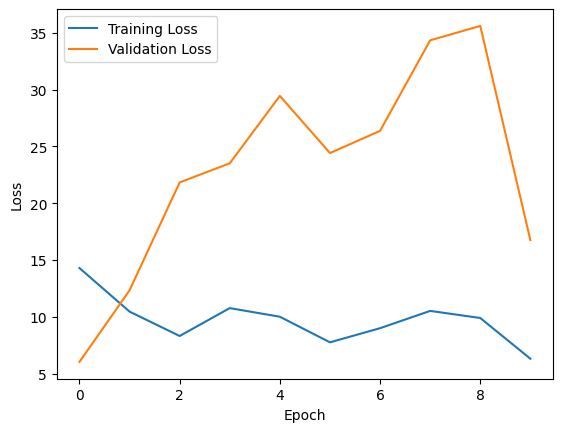

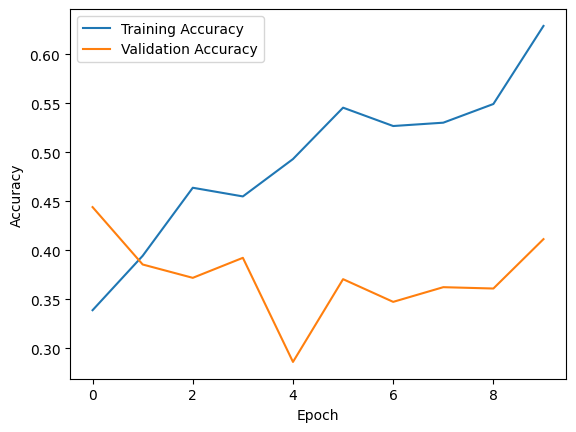

In [12]:
# Purpose: Plots the training and validation loss and accuracy across all epochs to show how well the neural network learns and performs on images it was not trained on.

import matplotlib.pyplot as plt

# Plot training and validation loss to track prediction errors
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Plot training and validation accuracy to track classification performance
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step


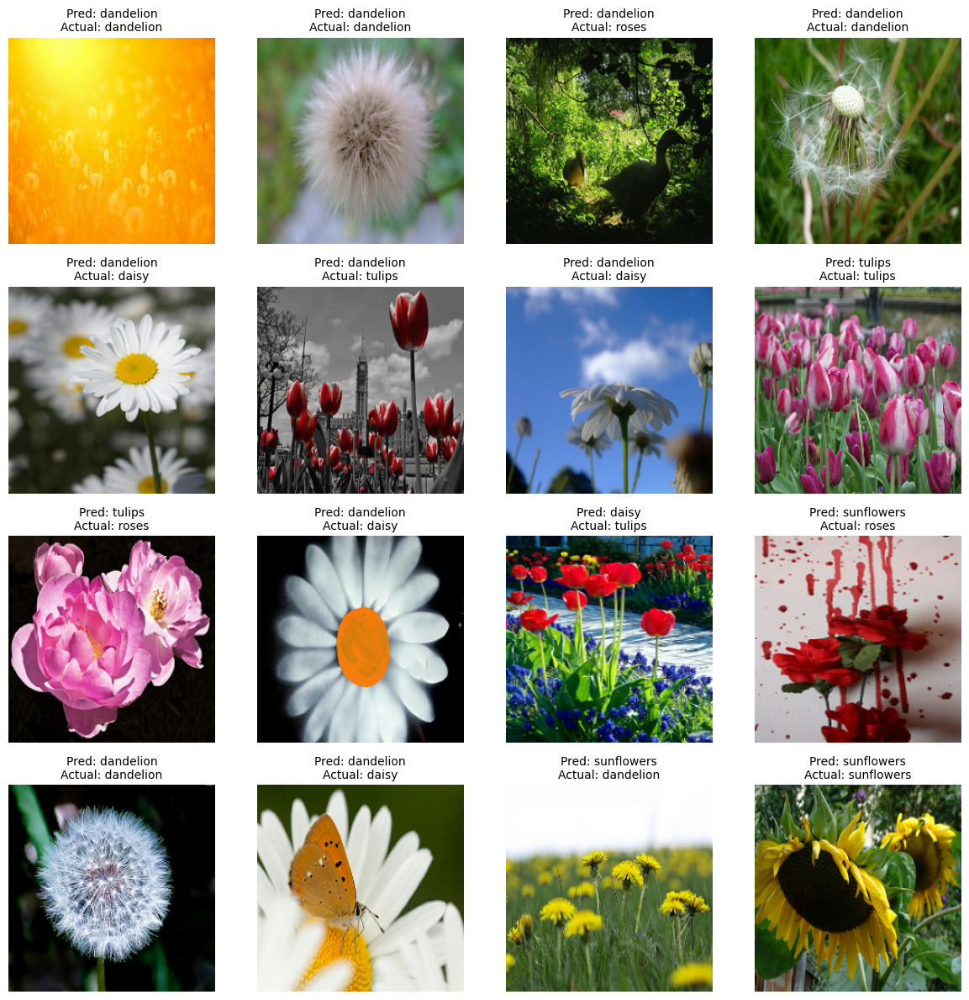

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


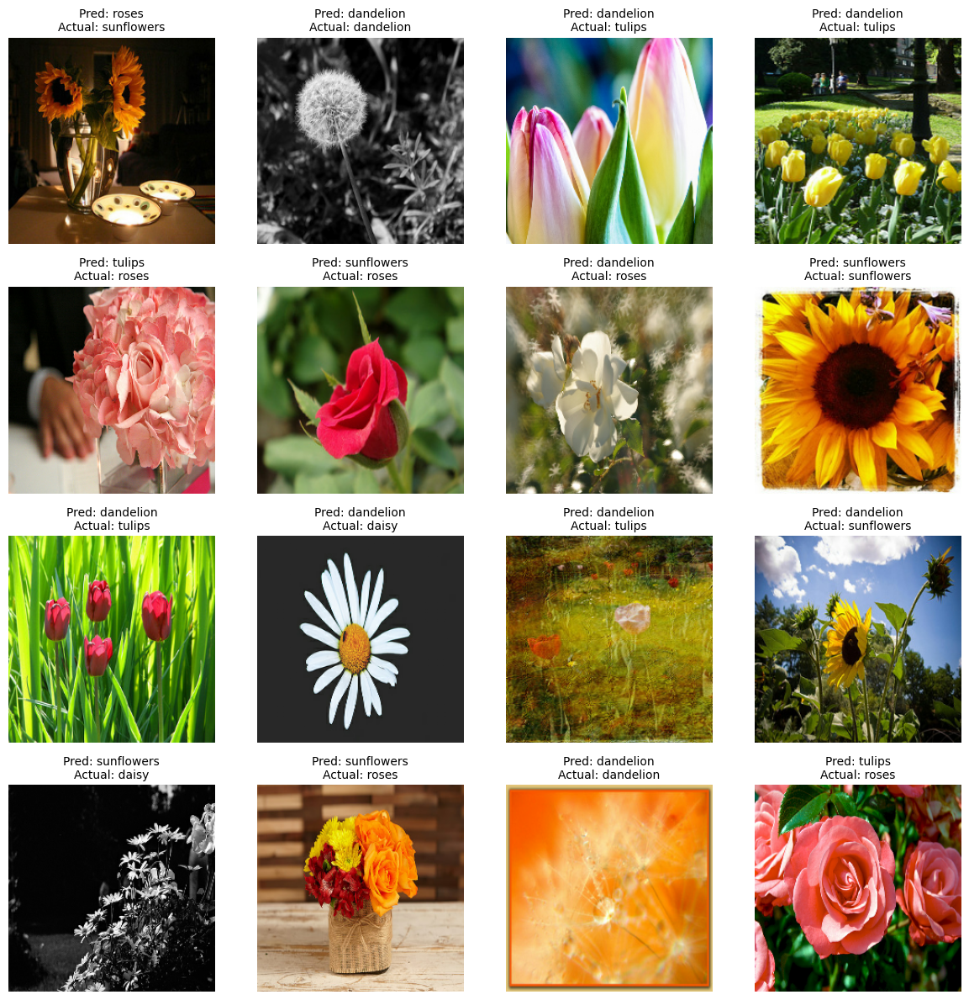

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


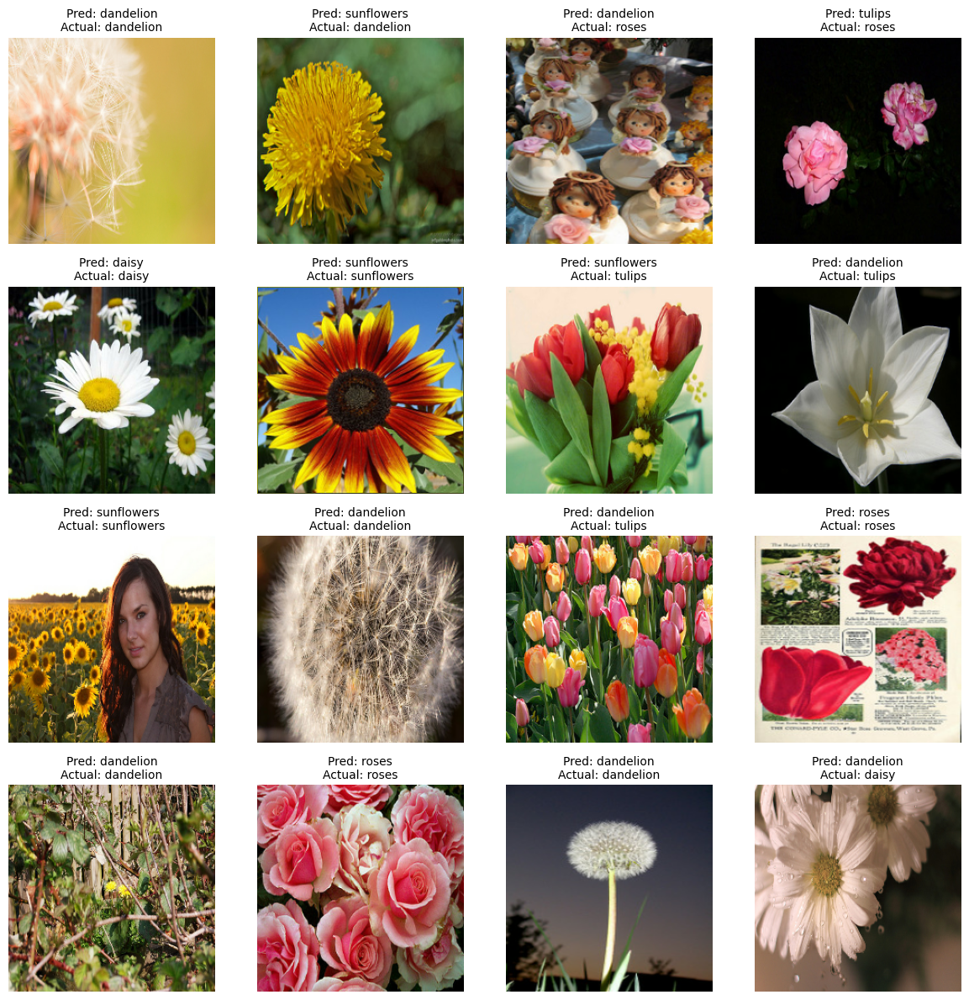

In [23]:
# Purpose: Tests the trained neural network on a batch of evaluation images, predicts each image's flower category, and displays the predicted and actual labels side by side to help assess how accurately the model classifies flowers.

import numpy as np
import matplotlib.pyplot as plt
import math

# Take one batch of images from the evaluation dataset
for images, labels in eval_dataset.take(3):

    # Ask the trained model to predict the flower category of each image
    batch_predictions = model.predict(images)

    # Find the category with the highest predicted probability for each image
    predicted_indices = np.argmax(batch_predictions, axis=1)

    # Count the number of images in the current batch
    num_images = images.shape[0]

    # Set the number of images to display in each row
    num_cols = 4

    # Calculate how many rows are needed to display all images
    num_rows = math.ceil(num_images / num_cols)

    # Create a figure large enough to display the images clearly
    plt.figure(figsize=(12, 3 * num_rows))

    # Loop through every image in the evaluation batch
    for i in range(num_images):

        # Create a position for the current image in the grid
        plt.subplot(num_rows, num_cols, i + 1)

        # Display the flower image
        plt.imshow(images[i].numpy())
        plt.axis("off")

        # Convert the predicted numeric label into a flower category name
        pred_class = CLASS_NAMES[predicted_indices[i]]

        # Convert the actual numeric label into the correct flower category name
        actual_class = CLASS_NAMES[int(labels[i].numpy())]

        # Display both the model's prediction and the correct category
        plt.title(
            f"Pred: {pred_class}\nActual: {actual_class}",
            fontsize=10
        )

    # Adjust spacing so the images and titles do not overlap
    plt.tight_layout()

    # Display the complete grid of evaluation images
    plt.show()